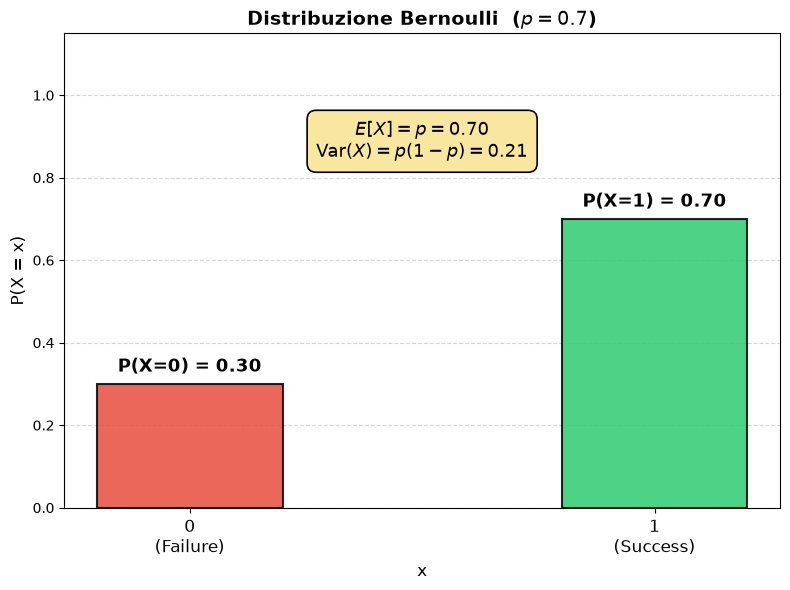

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Parametro
p = 0.7  # probabilità di successo

# Dati
x = [0, 1]
pmf = [1 - p, p]

# Calcolo media e varianza
media = p
varianza = p * (1 - p)

# Figura
fig, ax = plt.subplots(figsize=(8, 6))

# Barre
bars = ax.bar(x, pmf, width=0.4, color=['#e74c3c', '#2ecc71'],
              edgecolor='black', linewidth=1.5, alpha=0.85)

# Annotazioni sopra le barre
for xi, pi in zip(x, pmf):
    ax.text(xi, pi + 0.03, f'P(X={xi}) = {pi:.2f}',
            ha='center', fontsize=13, fontweight='bold')

# Testo con media e varianza
ax.text(0.5, 0.85,
        f'$E[X] = p = {media:.2f}$\n'
        f'$\\mathrm{{Var}}(X) = p(1-p) = {varianza:.2f}$',
        ha='center', fontsize=13,
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#f9e79f',
                  edgecolor='black', linewidth=1.2))

# Etichette
ax.set_xticks(x)
ax.set_xticklabels(['0\n(Failure)', '1\n(Success)'], fontsize=12)
ax.set_ylim(0, 1.15)
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('P(X = x)', fontsize=12)
ax.set_title(f'Distribuzione Bernoulli  ($p = {p}$)',
             fontsize=14, fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('./assets/bernoulli.png', dpi=150, bbox_inches='tight')
plt.show()

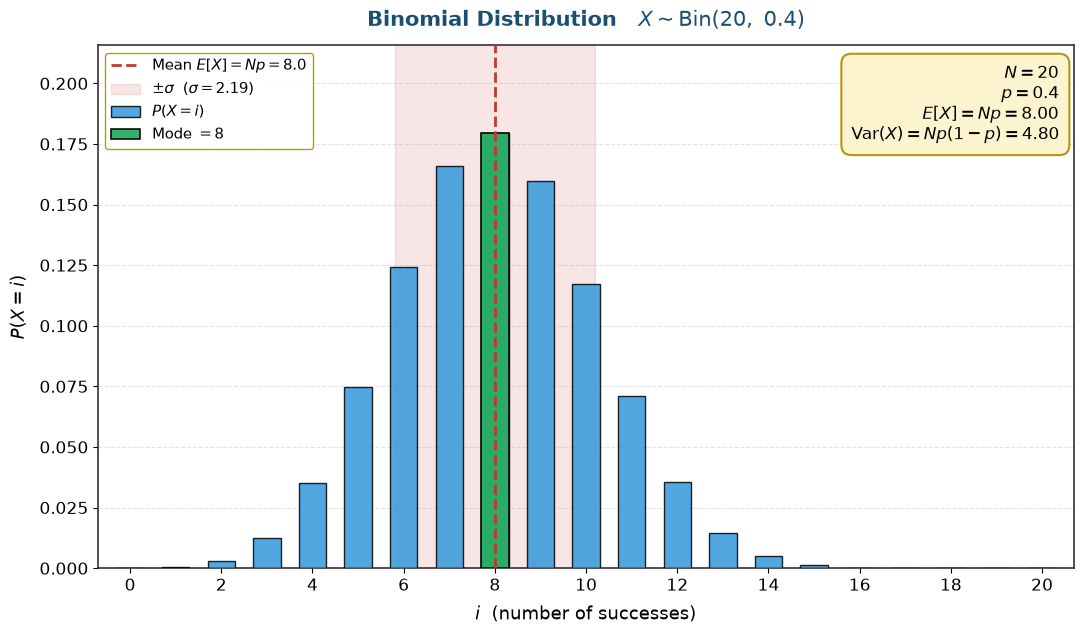

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binom

# ===== Parameters =====
N = 20      # number of trials
p = 0.4     # probability of success

# ===== Data =====
i = np.arange(0, N + 1)
pmf = binom.pmf(i, N, p)

# Mean and variance
mean = N * p
variance = N * p * (1 - p)
sigma = np.sqrt(variance)

# ===== Global style =====
plt.rcParams.update({
    'font.size': 12,
    'axes.edgecolor': '#333333',
    'axes.linewidth': 1.2,
})

# ===== Figure =====
fig, ax = plt.subplots(figsize=(11, 6.5))
fig.patch.set_facecolor('white')

# --- PMF bars ---
ax.bar(i, pmf, width=0.6, color='#3498DB',
       edgecolor='black', linewidth=1.0, alpha=0.85,
       label='$P(X = i)$', zorder=3)

# --- Highlight the mode ---
mode = int(np.floor((N + 1) * p))
ax.bar(mode, pmf[mode], width=0.6, color='#27AE60',
       edgecolor='black', linewidth=1.2, alpha=0.95,
       label=f'Mode $= {mode}$', zorder=4)

# --- Mean vertical line ---
ax.axvline(mean, color='#C0392B', linestyle='--', linewidth=2,
           label=f'Mean $E[X] = Np = {mean:.1f}$', zorder=5)

# --- ±sigma band ---
ax.axvspan(mean - sigma, mean + sigma, color='#C0392B', alpha=0.12,
           label=f'$\\pm\\sigma$  ($\\sigma = {sigma:.2f}$)', zorder=1)

# --- Info box ---
info = (f'$N = {N}$\n'
        f'$p = {p}$\n'
        f'$E[X] = Np = {mean:.2f}$\n'
        f'$\\mathrm{{Var}}(X) = Np(1-p) = {variance:.2f}$')
box = dict(boxstyle='round,pad=0.6', facecolor='#FCF3CF',
           edgecolor='#B7950B', linewidth=1.5)
ax.text(0.985, 0.965, info, transform=ax.transAxes,
        ha='right', va='top', fontsize=12, bbox=box,
        family='monospace', zorder=8)

# --- Labels and title ---
ax.set_xlabel('$i$  (number of successes)', fontsize=13, labelpad=8)
ax.set_ylabel('$P(X = i)$', fontsize=13, labelpad=8)
ax.set_title(f'Binomial Distribution   '
             f'$X \\sim \\mathrm{{Bin}}({N},\\ {p})$',
             fontsize=15, fontweight='bold', pad=14, color='#1B4F72')

# --- Ticks, grid, limits ---
ax.set_xticks(np.arange(0, N + 1, 2))
ax.grid(axis='y', linestyle='--', alpha=0.35, zorder=0)
ax.set_axisbelow(True)
ax.set_ylim(0, pmf.max() * 1.20)
ax.set_xlim(-0.7, N + 0.7)

# --- Legend ---
ax.legend(fontsize=10.5, loc='upper left', framealpha=0.95,
          edgecolor='#B7950B')

plt.tight_layout()
plt.savefig('./assets/binomial.png', dpi=160, bbox_inches='tight',
            facecolor='white')
plt.show()

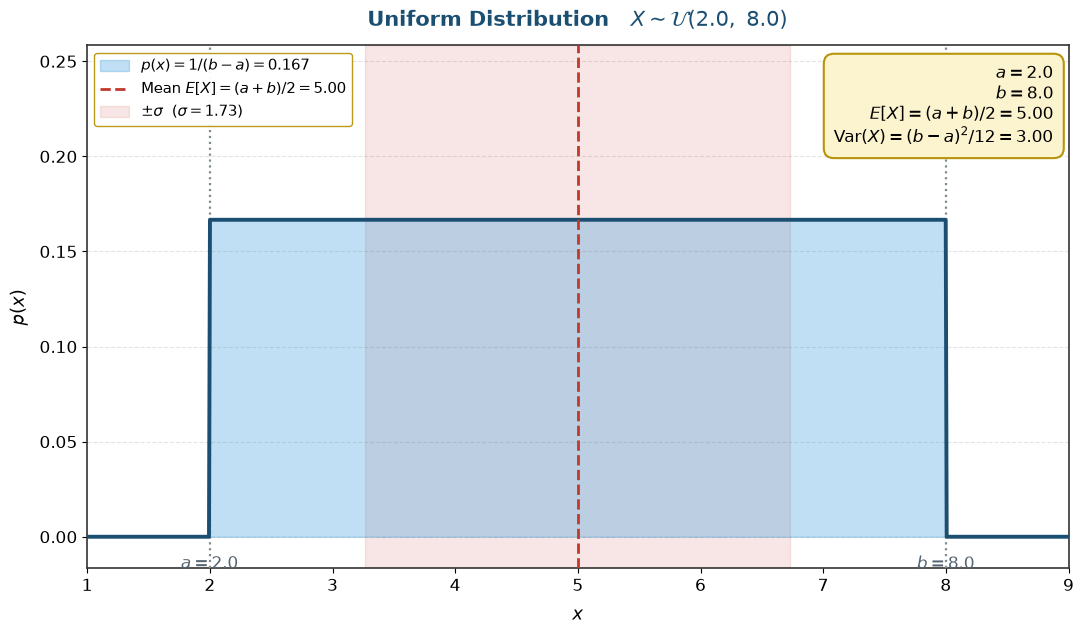

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import os

# ===== Parameters =====
a = 2.0   # lower bound
b = 8.0   # upper bound

# Mean and variance
mean = (a + b) / 2
variance = (b - a) ** 2 / 12
sigma = np.sqrt(variance)

# ===== Data =====
x = np.linspace(a - 1, b + 1, 1000)
pdf = np.where((x >= a) & (x <= b), 1 / (b - a), 0)
height = 1 / (b - a)

# ===== Global style =====
plt.rcParams.update({
    'font.size': 12,
    'axes.edgecolor': '#333333',
    'axes.linewidth': 1.2,
})

# ===== Figure =====
fig, ax = plt.subplots(figsize=(11, 6.5))
fig.patch.set_facecolor('white')

# --- Filled area under the PDF ---
ax.fill_between(x, pdf, where=(x >= a) & (x <= b),
                color='#3498DB', alpha=0.30,
                label=f'$p(x) = 1/(b-a) = {height:.3f}$', zorder=2)

# --- PDF curve ---
ax.plot(x, pdf, color='#1B4F72', linewidth=2.8, zorder=4)

# --- Vertical dashed lines at a and b ---
ax.axvline(a, color='#7F8C8D', linestyle=':', linewidth=1.6, zorder=3)
ax.axvline(b, color='#7F8C8D', linestyle=':', linewidth=1.6, zorder=3)
ax.text(a, -height * 0.06, f'$a = {a}$', ha='center', va='top',
        fontsize=12, color='#566573', fontweight='bold')
ax.text(b, -height * 0.06, f'$b = {b}$', ha='center', va='top',
        fontsize=12, color='#566573', fontweight='bold')

# --- Mean vertical line ---
ax.axvline(mean, color='#C0392B', linestyle='--', linewidth=2,
           label=f'Mean $E[X] = (a+b)/2 = {mean:.2f}$', zorder=5)

# --- ±sigma band ---
ax.axvspan(mean - sigma, mean + sigma, color='#C0392B', alpha=0.12,
           label=f'$\\pm\\sigma$  ($\\sigma = {sigma:.2f}$)', zorder=1)

# --- Info box ---
info = (f'$a = {a}$\n'
        f'$b = {b}$\n'
        f'$E[X] = (a+b)/2 = {mean:.2f}$\n'
        f'$\\mathrm{{Var}}(X) = (b-a)^2/12 = {variance:.2f}$')
box = dict(boxstyle='round,pad=0.6', facecolor='#FCF3CF',
           edgecolor='#B7950B', linewidth=1.5)
ax.text(0.985, 0.965, info, transform=ax.transAxes,
        ha='right', va='top', fontsize=12, bbox=box,
        family='monospace', zorder=8)

# --- Labels and title ---
ax.set_xlabel('$x$', fontsize=13, labelpad=8)
ax.set_ylabel('$p(x)$', fontsize=13, labelpad=8)
ax.set_title(f'Uniform Distribution   '
             f'$X \\sim \\mathcal{{U}}({a},\\ {b})$',
             fontsize=15, fontweight='bold', pad=14, color='#1B4F72')

# --- Grid and limits ---
ax.grid(axis='y', linestyle='--', alpha=0.35, zorder=0)
ax.set_axisbelow(True)
ax.set_ylim(-height * 0.10, height * 1.55)
ax.set_xlim(a - 1, b + 1)

# --- Legend ---
ax.legend(fontsize=10.5, loc='upper left', framealpha=0.95,
          edgecolor='#B7950B')

plt.tight_layout()

# ===== Save to ./assets/ =====
os.makedirs('./assets', exist_ok=True)
plt.savefig('./assets/uniform.png', dpi=160, bbox_inches='tight',
            facecolor='white')

plt.show()

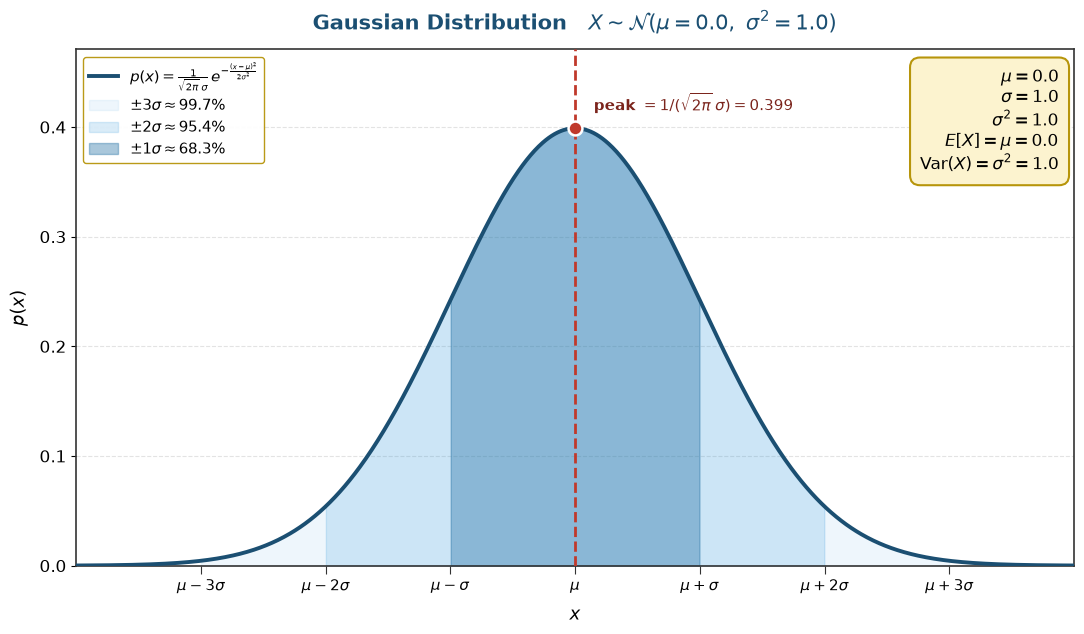

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import os

# ===== Parameters =====
mu = 0.0
sigma = 1.0
variance = sigma ** 2

# ===== Data =====
x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 1000)
pdf = (1 / (np.sqrt(2 * np.pi) * sigma)) * \
      np.exp(-(x - mu) ** 2 / (2 * sigma ** 2))
peak = 1 / (np.sqrt(2 * np.pi) * sigma)

# ===== Global style =====
plt.rcParams.update({
    'font.size': 12,
    'axes.edgecolor': '#333333',
    'axes.linewidth': 1.2,
})

# ===== Figure =====
fig, ax = plt.subplots(figsize=(11, 6.5))
fig.patch.set_facecolor('white')

# --- Sigma bands ---
bands = [
    (3, '#5DADE2', 0.10, r'$\pm 3\sigma \approx 99.7\%$'),
    (2, '#3498DB', 0.18, r'$\pm 2\sigma \approx 95.4\%$'),
    (1, '#2874A6', 0.40, r'$\pm 1\sigma \approx 68.3\%$'),
]
for k, color, alpha, label in bands:
    mask = (x >= mu - k * sigma) & (x <= mu + k * sigma)
    ax.fill_between(x, pdf, where=mask, color=color, alpha=alpha,
                    label=label, zorder=2)

# --- PDF curve ---
ax.plot(x, pdf, color='#1B4F72', linewidth=2.8, zorder=4,
        label=r'$p(x) = \frac{1}{\sqrt{2\pi}\,\sigma}\,'
              r'e^{-\frac{(x-\mu)^2}{2\sigma^2}}$')

# --- Mean vertical line ---
ax.axvline(mu, color='#C0392B', linestyle='--', linewidth=2,
           zorder=3, label=f'$\\mu = {mu}$')

# --- Peak marker ---
ax.plot(mu, peak, 'o', color='#C0392B', markersize=10,
        markeredgecolor='white', markeredgewidth=1.8, zorder=6)

# --- Peak text (no arrow) ---
ax.text(mu + 0.15, peak * 1.03,
        f'peak $= 1/(\\sqrt{{2\\pi}}\\,\\sigma) = {peak:.3f}$',
        fontsize=11, color='#7B241C', fontweight='bold',
        ha='left', va='bottom', zorder=7)

# --- Custom x-axis ticks ---
ticks = [mu - 3*sigma, mu - 2*sigma, mu - sigma, mu,
         mu + sigma, mu + 2*sigma, mu + 3*sigma]
labels = [r'$\mu-3\sigma$', r'$\mu-2\sigma$', r'$\mu-\sigma$',
          r'$\mu$', r'$\mu+\sigma$', r'$\mu+2\sigma$', r'$\mu+3\sigma$']
ax.set_xticks(ticks)
ax.set_xticklabels(labels, fontsize=11)
ax.tick_params(axis='x', length=6, color='#333333')

# --- Info box ---
info = (f'$\\mu = {mu}$\n'
        f'$\\sigma = {sigma}$\n'
        f'$\\sigma^2 = {variance}$\n'
        f'$E[X] = \\mu = {mu}$\n'
        f'$\\mathrm{{Var}}(X) = \\sigma^2 = {variance}$')
box = dict(boxstyle='round,pad=0.6', facecolor='#FCF3CF',
           edgecolor='#B7950B', linewidth=1.5)
ax.text(0.985, 0.965, info, transform=ax.transAxes,
        ha='right', va='top', fontsize=12, bbox=box,
        family='monospace', zorder=8)

# --- Labels and title ---
ax.set_xlabel('$x$', fontsize=13, labelpad=8)
ax.set_ylabel('$p(x)$', fontsize=13, labelpad=8)
ax.set_title(f'Gaussian Distribution   '
             f'$X \\sim \\mathcal{{N}}(\\mu={mu},\\ \\sigma^2={variance})$',
             fontsize=15, fontweight='bold', pad=14, color='#1B4F72')

# --- Grid and limits ---
ax.grid(axis='y', linestyle='--', alpha=0.35, zorder=0)
ax.set_axisbelow(True)
ax.set_ylim(0, peak * 1.18)
ax.set_xlim(mu - 4 * sigma, mu + 4 * sigma)

# --- Legend ---
handles, labels_leg = ax.get_legend_handles_labels()
order = [3, 0, 1, 2]
ax.legend([handles[i] for i in order], [labels_leg[i] for i in order],
          fontsize=10.5, loc='upper left', framealpha=0.95,
          edgecolor='#B7950B')

plt.tight_layout()

# ===== Save to ./assets/ =====
os.makedirs('./assets', exist_ok=True)
plt.savefig('./assets/gaussian.png', dpi=160, bbox_inches='tight',
            facecolor='white')

plt.show()